In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os, sys, shutil, subprocess, json, random, time, gc, copy, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet50_Weights, EfficientNet_B0_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DRIVE_PROJECT = Path('/content/drive/MyDrive/DPD-Small')
LOCAL_PROJECT = Path('/content/DPD-Small')
BASE_RESULTS = Path('/content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1')
RESULTS = BASE_RESULTS / 'shared_dataset_audit'
SEED = 42
NUM_WORKERS = 2
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

assert DRIVE_PROJECT.exists(), f'Cannot find Drive project: {DRIVE_PROJECT}'
assert RESULTS.resolve() != DRIVE_PROJECT.resolve(), 'Results folder cannot be the source dataset.'
assert 'ResNet50_V2_Three_Strategies_Stage1' in str(BASE_RESULTS), 'Safety: isolated output root required.'
# Each training function refuses to overwrite a nonempty run directory.
assert DEVICE.type == 'cuda', 'Enable a GPU: Runtime > Change runtime type > GPU'
RESULTS.mkdir(parents=True, exist_ok=True)
for folder in [
    'experiments/crop', 'experiments/disease',
    'development/combined_validation', 'development/experiment_comparisons',
    'fine_tuning', 'final',
    'official_evaluation/metrics', 'official_evaluation/predictions',
    'official_evaluation/confusion_matrices/seen',
    'official_evaluation/confusion_matrices/unseen',
    'official_evaluation/misclassification/seen',
    'official_evaluation/misclassification/unseen',
]:
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

DEVELOPMENT_DIR = RESULTS / 'development'
OFFICIAL_DIR = RESULTS / 'official_evaluation'
METRICS_DIR = OFFICIAL_DIR / 'metrics'
PREDICTIONS_DIR = OFFICIAL_DIR / 'predictions'
CONFUSION_DIR = OFFICIAL_DIR / 'confusion_matrices'
MISCLASS_DIR = OFFICIAL_DIR / 'misclassification'


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('Project:', DRIVE_PROJECT)
print('NEW isolated V2 strategy comparison root:', BASE_RESULTS)
print('ResNet-50 V2 | frozen, partial, full | AMP:', AMP)

GPU: Tesla T4
PyTorch: 2.14.1+cu130
Project: /content/drive/MyDrive/DPD-Small
NEW isolated V2 strategy comparison root: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1
ResNet-50 V2 | frozen, partial, full | AMP: True


In [ ]:
LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

def find_child(parent, name):
    hits = [p for p in parent.iterdir() if p.name.lower() == name.lower()]
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected {name} in {parent}; found {hits}')
    return hits[0]

start_copy = time.time()
for dirname in ['images', 'splits_v2']:
    src = find_child(DRIVE_PROJECT, dirname)
    dst = LOCAL_PROJECT / dirname
    dst.mkdir(parents=True, exist_ok=True)
    print(f'Copy/resume: {src} -> {dst}', flush=True)
    subprocess.run([
        'rsync', '-rt', '--size-only', '--info=progress2',
        str(src) + '/', str(dst) + '/'
    ], check=True)

for filename in ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']:
    src = find_child(DRIVE_PROJECT, filename)
    shutil.copy2(src, LOCAL_PROJECT / filename)
    print('Copied CSV:', filename)

print(f'Copy complete in {(time.time()-start_copy)/60:.1f} min')

Copy/resume: /content/drive/MyDrive/DPD-Small/images -> /content/DPD-Small/images
Copy/resume: /content/drive/MyDrive/DPD-Small/splits_v2 -> /content/DPD-Small/splits_v2
Copied CSV: DPD_Small_train.csv
Copied CSV: DPD_Small_test_seen.csv
Copied CSV: DPD_Small_test_unseen.csv
Copy complete in 13.2 min


In [ ]:
COLUMNS = ['filename','crop_id','disease_id','composition_id',
           'crop_name','disease_name','composition_name']

def read_original_csv(path):
    # Original lecturer files have no header; also handles an unexpected header safely.
    with open(path, 'r', encoding='utf-8-sig') as f:
        first = f.readline().strip().split(',')
    has_header = first[0].strip().lower() == 'filename'
    df = pd.read_csv(path, header=0 if has_header else None,
                     names=COLUMNS, encoding='utf-8-sig')
    for col in ['crop_id','disease_id','composition_id']:
        df[col] = pd.to_numeric(df[col], errors='raise').astype(int)
    return df

train_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/train_fit.csv')
val_seen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_seen.csv')
val_unseen_df = pd.read_csv(LOCAL_PROJECT/'splits_v2/val_unseen.csv')
full_train_df = read_original_csv(LOCAL_PROJECT/'DPD_Small_train.csv')

expected = {'train':6905,'val_seen':695,'val_unseen':400,'full_train':8000}
datasets = {'train':train_df,'val_seen':val_seen_df,'val_unseen':val_unseen_df,
            'full_train':full_train_df}
for name, df in datasets.items():
    assert len(df) == expected[name], f'{name}: got {len(df)}, expected {expected[name]}'
    assert set(COLUMNS).issubset(df.columns), f'Missing metadata columns in {name}'
    assert df.filename.is_unique, f'Duplicate filenames in {name}'
    print(f'{name:12s}: {len(df):,} images')

file_sets = [set(df.filename) for df in (train_df,val_seen_df,val_unseen_df)]
assert not any(file_sets[i] & file_sets[j] for i in range(3) for j in range(i+1,3))
assert set().union(*file_sets) == set(full_train_df.filename)

def pairs(df):
    return set(map(tuple,df[['crop_id','disease_id']].astype(int).to_numpy()))

assert pairs(val_seen_df).issubset(pairs(train_df))
assert pairs(val_unseen_df).isdisjoint(pairs(train_df)|pairs(val_seen_df))
assert set(val_unseen_df.crop_id).issubset(set(train_df.crop_id))
assert set(val_unseen_df.disease_id).issubset(set(train_df.disease_id))
print('Split separation and unseen-composition coverage: PASS')
display(train_df.head(3))

train       : 6,905 images
val_seen    : 695 images
val_unseen  : 400 images
full_train  : 8,000 images
Split separation and unseen-composition coverage: PASS


,filename,crop_id,disease_id,composition_id,crop_name,disease_name,composition_name
0,BLSD_banana_sigatoka_615.jpeg,2,26,28,banana,sigatoka,banana_sigatoka
1,PD_paddy_bacterial_panicle_blight_1285.jpg,33,120,195,paddy,bacterial_panicle_blight,paddy_bacterial_panicle_blight
2,PWV2_peach_leaf_curl_6128.jpg,36,57,219,peach,curl,peach_curl


In [ ]:
image_dir = LOCAL_PROJECT / 'images'
assert image_dir.is_dir(), f'No images folder: {image_dir}'
image_lookup = {}
duplicates = []
for p in tqdm(image_dir.rglob('*'), desc='Indexing local images'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}:
        if p.name in image_lookup:
            duplicates.append(p.name)
        image_lookup[p.name] = p
assert not duplicates, f'Duplicate basenames: {duplicates[:8]}'
needed = set().union(*(set(df.filename) for df in datasets.values()))
missing = needed - set(image_lookup)
print('Indexed:', len(image_lookup), '| Required unique:',len(needed),'| Missing:',len(missing))
assert not missing, f'Missing images (rerun Cell 3): {list(missing)[:10]}'
print('All required images are available locally.')

Indexing local images: 0it [00:00, ?it/s]

Indexed: 11469 | Required unique: 8000 | Missing: 0
All required images are available locally.


In [ ]:
MEAN = (0.485,0.456,0.406)
STD = (0.229,0.224,0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85,1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN,STD),
])
def de_normalize(t):
    mu = torch.tensor(MEAN).view(3,1,1)
    sd = torch.tensor(STD).view(3,1,1)
    return (t.detach().cpu()*sd+mu).clamp(0,1).permute(1,2,0).numpy()
print('Transforms ready: random train augmentation; deterministic validation/test.')

Transforms ready: random train augmentation; deterministic validation/test.


In [ ]:
crop_ids = sorted(map(int,full_train_df.crop_id.unique()))
disease_ids = sorted(map(int,full_train_df.disease_id.unique()))
assert len(crop_ids)==55, f'Expected 55 crops, got {len(crop_ids)}'
assert len(disease_ids)==175, f'Expected 175 diseases, got {len(disease_ids)}'
crop_to_idx = {c:i for i,c in enumerate(crop_ids)}
disease_to_idx = {d:i for i,d in enumerate(disease_ids)}
idx_to_crop = {i:c for c,i in crop_to_idx.items()}
idx_to_disease = {i:d for d,i in disease_to_idx.items()}
(RESULTS/'class_mapping.json').write_text(json.dumps({'crop_ids':crop_ids,'disease_ids':disease_ids},indent=2))

class PlantDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(image_lookup[str(row.filename)]) as im:
            x = self.transform(im.convert('RGB'))
        return (x, crop_to_idx[int(row.crop_id)], disease_to_idx[int(row.disease_id)])

def loader_for(df, train=False, batch_size=32):
    return DataLoader(
        PlantDataset(df, train_transform if train else eval_transform),
        batch_size=batch_size, shuffle=train, num_workers=NUM_WORKERS,
        pin_memory=True, persistent_workers=(NUM_WORKERS>0)
    )

seen_loader = loader_for(val_seen_df)
unseen_loader = loader_for(val_unseen_df)
print('Class mappings: crops=',len(crop_ids),'diseases=',len(disease_ids))
print('Validation batches:',len(seen_loader),'seen and',len(unseen_loader),'unseen')

# Save stable class mapping also in the shared folder. Each backbone will copy it to its own results directory.


Class mappings: crops= 55 diseases= 175
Validation batches: 22 seen and 13 unseen


In [ ]:
BACKBONE = 'resnet50'
WEIGHTS_NAME = 'IMAGENET1K_V2'
STRATEGIES = ('frozen', 'partial', 'full')

# Active per-strategy output directory. Set by the dedicated training cells.
RESULTS = BASE_RESULTS / 'frozen'


def activate_strategy(strategy):
    global RESULTS, ACTIVE_STRATEGY
    assert strategy in STRATEGIES
    ACTIVE_STRATEGY = strategy
    RESULTS = BASE_RESULTS / strategy
    for sub in ('experiments/crop', 'experiments/disease', 'development/combined_validation'):
        (RESULTS / sub).mkdir(parents=True, exist_ok=True)
    (RESULTS / 'class_mapping.json').write_text(json.dumps({
        'crop_ids': crop_ids, 'disease_ids': disease_ids,
        'backbone':'resnet50', 'pretrained_weights':WEIGHTS_NAME,
        'strategy':strategy}, indent=2))
    print('Active strategy:', strategy, '| output:', RESULTS)


def make_model(task, pretrained=True, dropout=0.2, strategy=None):
    strategy = strategy or ACTIVE_STRATEGY
    assert strategy in STRATEGIES
    assert task in ('crop', 'disease')
    weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = models.resnet50(weights=weights)
    width = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(width, 55 if task=='crop' else 175))
    if strategy == 'frozen':
        for p in model.parameters(): p.requires_grad = False
        for p in model.fc.parameters(): p.requires_grad = True
    elif strategy == 'partial':
        for p in model.parameters(): p.requires_grad = False
        for p in model.layer4.parameters(): p.requires_grad = True
        for p in model.fc.parameters(): p.requires_grad = True
    else:
        for p in model.parameters(): p.requires_grad = True
    return model.to(DEVICE)


def make_optimizer(model, cfg):
    backbone_params = [p for name,p in model.named_parameters() if p.requires_grad and not name.startswith('fc.')]
    head_params = [p for name,p in model.named_parameters() if p.requires_grad and name.startswith('fc.')]
    assert head_params, 'Classifier head must be trainable'
    groups = []
    if backbone_params: groups.append({'params':backbone_params,'lr':cfg['backbone_lr']})
    groups.append({'params':head_params,'lr':cfg['head_lr']})
    return torch.optim.AdamW(groups,weight_decay=cfg['weight_decay'])

def freeze_bn_stats(model):
    """Frozen BatchNorm layers must not update running_mean/var during model.train()."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            # BN running statistics are frozen for BN layers with frozen parameters.
            if not any(p.requires_grad for p in module.parameters(recurse=False)):
                module.eval()

def harmonic(a,b):
    return 0.0 if a+b==0 else 2*a*b/(a+b)

def experiment_path(task, name):
    return RESULTS/'experiments'/task/name

@torch.no_grad()
def evaluate_task(model, loader, task):
    model.eval()
    total_n = total_loss = correct1 = correct5 = 0
    criterion = nn.CrossEntropyLoss()
    for x, yc, yd in loader:
        x = x.to(DEVICE,non_blocking=True)
        y = (yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits = model(x)
            loss = criterion(logits,y)
        total_n += y.size(0)
        total_loss += loss.item()*y.size(0)
        top5 = logits.topk(5,dim=1).indices
        correct1 += (top5[:,0]==y).sum().item()
        correct5 += (top5==y[:,None]).any(1).sum().item()
    return {'loss':total_loss/total_n, 'top1':correct1/total_n,'top5':correct5/total_n}

def training_epoch(model, loader, task, optimizer, scaler, label):
    model.train()
    freeze_bn_stats(model)
    criterion = nn.CrossEntropyLoss()
    total_n=correct=0
    total_loss=0.0
    bar=tqdm(loader,desc=label,leave=False)
    for x,yc,yd in bar:
        x=x.to(DEVICE,non_blocking=True)
        y=(yc if task=='crop' else yd).to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
            loss=criterion(logits,y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        n=y.size(0)
        total_n+=n
        total_loss+=float(loss.detach())*n
        correct+=(logits.argmax(1)==y).sum().item()
        bar.set_postfix(loss=f'{total_loss/total_n:.3f}',acc=f'{correct/total_n:.1%}')
    return {'loss':total_loss/total_n,'top1':correct/total_n}

@torch.no_grad()
def predict_log_probs(model, loader):
    model.eval()
    outputs=[]
    for x,_,_ in loader:
        x=x.to(DEVICE,non_blocking=True)
        with torch.autocast('cuda',enabled=AMP):
            logits=model(x)
        outputs.append(F.log_softmax(logits.float(),dim=1).cpu().numpy())
    return np.concatenate(outputs,axis=0)

def save_ckpt(path, model, task, cfg, epoch, metric=None):
    path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({
        'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
        'task':task, 'backbone':BACKBONE, 'pretrained_weights':WEIGHTS_NAME, 'fine_tuning':ACTIVE_STRATEGY,
        'epoch':int(epoch), 'config':copy.deepcopy(cfg),
        'crop_ids':crop_ids,'disease_ids':disease_ids,'seed':SEED,
        'selection_metric':metric
    },path)

def load_model(path, expected_task):
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck['task']==expected_task
    assert ck.get('backbone') == BACKBONE, 'Wrong backbone checkpoint!'
    assert ck.get('pretrained_weights') == WEIGHTS_NAME and ck.get('fine_tuning') == ACTIVE_STRATEGY, 'Wrong weights / strategy checkpoint!'
    assert ck['crop_ids']==crop_ids and ck['disease_ids']==disease_ids
    model=make_model(expected_task,pretrained=False,
                     dropout=ck.get('config',{}).get('dropout',0.2))
    model.load_state_dict(ck['state_dict'])
    return model,ck

def run_experiment(task,name,cfg):
    """Each model independently chooses best epoch by its own seen/unseen class H."""
    set_seed(SEED)
    out=experiment_path(task,name)
    if out.exists() and any(out.iterdir()):
        raise FileExistsError(f'Nonempty experiment folder: {out}. For a new attempt, choose a NEW run name/folder; do not overwrite.')
    out.mkdir(parents=True,exist_ok=True)
    (out/'config.json').write_text(json.dumps(cfg,indent=2))
    model=make_model(task,pretrained=True,dropout=cfg['dropout'])
    optimizer=make_optimizer(model,cfg)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=cfg['epochs'])
    scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    train_loader=loader_for(train_df,train=True,batch_size=cfg['batch_size'])
    best_h=-1.0; best_epoch=None; patience_count=0; history=[]
    try:
        for epoch in range(1,cfg['epochs']+1):
            t=time.time()
            tr=training_epoch(model,train_loader,task,optimizer,scaler,f'{task.upper()} {name} {epoch}/{cfg["epochs"]}')
            sv=evaluate_task(model,seen_loader,task)
            uv=evaluate_task(model,unseen_loader,task)
            h=harmonic(sv['top1'],uv['top1'])
            improved=h>best_h+1e-9
            if improved:
                best_h=h;best_epoch=epoch;patience_count=0
                save_ckpt(out/'best.pt',model,task,cfg,epoch,metric=h)
                # Validation predictions are stored for pairing, never from test images.
                np.savez_compressed(out/'best_validation.npz',
                    seen=predict_log_probs(model,seen_loader),
                    unseen=predict_log_probs(model,unseen_loader))
            else:
                patience_count+=1
            history.append({
                'epoch':epoch,'train_loss':tr['loss'],'train_acc':tr['top1'],
                'seen_loss':sv['loss'],'seen_acc':sv['top1'],'seen_top5':sv['top5'],
                'unseen_loss':uv['loss'],'unseen_acc':uv['top1'],'unseen_top5':uv['top5'],
                'harmonic_mean':h,'best_h':best_h,'seconds':time.time()-t
            })
            pd.DataFrame(history).to_csv(out/'history.csv',index=False)
            scheduler.step()
            print(f'{task.upper():7s} {name} | Epoch {epoch:02d}/{cfg["epochs"]} | '
                  f'Train Loss {tr["loss"]:.4f} | Train Acc {tr["top1"]:.2%} | '
                  f'Seen Val {sv["top1"]:.2%} | Unseen Val {uv["top1"]:.2%} | '
                  f'H {h:.2%} | Best H {best_h:.2%} | Patience {patience_count}/{cfg["patience"]}',flush=True)
            if cfg['early_stopping'] and patience_count>=cfg['patience']:
                print(f'EARLY STOPPING: {task} | best epoch={best_epoch} | best H={best_h:.2%}')
                break
    finally:
        del model,optimizer,scheduler,scaler,train_loader
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    print(f'FINISHED {task}/{name}: best epoch={best_epoch} | H={best_h:.2%}')
    return pd.DataFrame(history)

def plot_experiment(task,name):
    df=pd.read_csv(experiment_path(task,name)/'history.csv')
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for col in ['train_loss','seen_loss','unseen_loss']:
        axes[0].plot(df.epoch,df[col],label=col)
    for col in ['train_acc','seen_acc','unseen_acc']:
        axes[1].plot(df.epoch,df[col]*100,label=col)
    axes[2].plot(df.epoch,df.harmonic_mean*100,label='Current H')
    axes[2].plot(df.epoch,df.best_h*100,label='Best H',linestyle='--')
    for ax,title in zip(axes,['Cross-entropy loss','Accuracy (%)','Individual harmonic mean (%)']):
        ax.set_title(title);ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
    plt.suptitle(f'{task.upper()} — {name}');plt.tight_layout()
    plt.savefig(experiment_path(task,name)/'curves.png',dpi=180)
    plt.show()

print(BACKBONE, WEIGHTS_NAME, 'three-strategy functions ready; no CNN trained yet.')

resnet50 IMAGENET1K_V2 three-strategy functions ready; no CNN trained yet.


In [ ]:
STAGE1_CROP = dict(backbone_lr=1e-5, head_lr=1e-3, batch_size=16,
                   epochs=30, patience=15, early_stopping=True,
                   weight_decay=1e-4, dropout=0.3)
STAGE1_DISEASE = dict(backbone_lr=1e-5, head_lr=1e-3, batch_size=16,
                      epochs=30, patience=15, early_stopping=True,
                      weight_decay=1e-4, dropout=0.2)
RUN_NAMES = {s: {'crop':f'ResNet50_V2_{s}_crop_C4_aug_P15',
                 'disease':f'ResNet50_V2_{s}_disease_D1_aug_P15'}
             for s in STRATEGIES}

# Copy this configuration only; no tuning or official labels here.
print('CROP CONFIG:', STAGE1_CROP)
print('DISEASE CONFIG:', STAGE1_DISEASE)
print('Weights:', WEIGHTS_NAME)
print('Strategies:', STRATEGIES)


CROP CONFIG: {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 16, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.3}
DISEASE CONFIG: {'backbone_lr': 1e-05, 'head_lr': 0.001, 'batch_size': 16, 'epochs': 30, 'patience': 15, 'early_stopping': True, 'weight_decay': 0.0001, 'dropout': 0.2}
Weights: IMAGENET1K_V2
Strategies: ('frozen', 'partial', 'full')


In [ ]:
def train_one(strategy, task):
    activate_strategy(strategy)
    cfg = STAGE1_CROP if task == 'crop' else STAGE1_DISEASE
    name = RUN_NAMES[strategy][task]
    run_dir = experiment_path(task, name)
    if (run_dir / 'best.pt').exists() and (run_dir / 'history.csv').exists():
        hist = pd.read_csv(run_dir / 'history.csv')
        # Skip existing runs to prevent accidental overwrite; report their best saved result.
        print('Existing checkpoint, skipping retraining:',run_dir)
        print('Completed history epochs:',len(hist),'| saved checkpoint:',run_dir/'best.pt')
        plot_experiment(task,name)
        return
    if run_dir.exists() and any(run_dir.iterdir()):
        raise FileExistsError(f'Incomplete run at {run_dir}. Do not overwrite; rename the run or inspect it.')
    run_experiment(task,name,cfg)
    plot_experiment(task,name)

# Training does not start until you run one of the six cells below.


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/"
    "AML_B1_ResNet50_V2_Three_Strategies_Stage1"
)

for strategy in ["frozen", "partial", "full"]:
    for task in ["crop", "disease"]:
        name = (
            f"ResNet50_V2_{strategy}_{task}_"
            f"{'C4' if task == 'crop' else 'D1'}_aug_P15"
        )
        folder = root / strategy / "experiments" / task / name

        history_file = folder / "history.csv"
        checkpoint_file = folder / "best.pt"

        if history_file.exists():
            history = pd.read_csv(history_file)
            epochs = len(history)
            best_epoch = (
                int(history.loc[
                    history["best_h"].idxmax(), "epoch"
                ])
                if len(history) else None
            )

            print(
                f"{strategy:8s} | {task:7s} | "
                f"{epochs:2d} epochs recorded | "
                f"Checkpoint: {checkpoint_file.exists()}"
            )
        else:
            print(
                f"{strategy:8s} | {task:7s} | "
                "No training history"
            )


frozen   | crop    | 30 epochs recorded | Checkpoint: True
frozen   | disease | 27 epochs recorded | Checkpoint: True
partial  | crop    | 24 epochs recorded | Checkpoint: True
partial  | disease | 30 epochs recorded | Checkpoint: True
full     | crop    | 30 epochs recorded | Checkpoint: True
full     | disease | 15 epochs recorded | Checkpoint: True


Active strategy: frozen | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/frozen
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 186MB/s]


CROP ResNet50_V2_frozen_crop_C4_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_frozen_crop_C4_aug_P15 | Epoch 01/30 | Train Loss 1.4240 | Train Acc 65.79% | Seen Val 74.53% | Unseen Val 55.25% | H 63.46% | Best H 63.46% | Patience 0/15


CROP ResNet50_V2_frozen_crop_C4_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_frozen_crop_C4_aug_P15 | Epoch 02/30 | Train Loss 0.6899 | Train Acc 84.00% | Seen Val 76.83% | Unseen Val 61.75% | H 68.47% | Best H 68.47% | Patience 0/15


... (52 outputs left out)

CROP ResNet50_V2_frozen_crop_C4_aug_P15 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_frozen_crop_C4_aug_P15 | Epoch 29/30 | Train Loss 0.1346 | Train Acc 96.97% | Seen Val 85.32% | Unseen Val 63.50% | H 72.81% | Best H 73.41% | Patience 10/15


CROP ResNet50_V2_frozen_crop_C4_aug_P15 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_frozen_crop_C4_aug_P15 | Epoch 30/30 | Train Loss 0.1325 | Train Acc 96.89% | Seen Val 85.32% | Unseen Val 63.50% | H 72.81% | Best H 73.41% | Patience 11/15
FINISHED crop/ResNet50_V2_frozen_crop_C4_aug_P15: best epoch=19 | H=73.41%


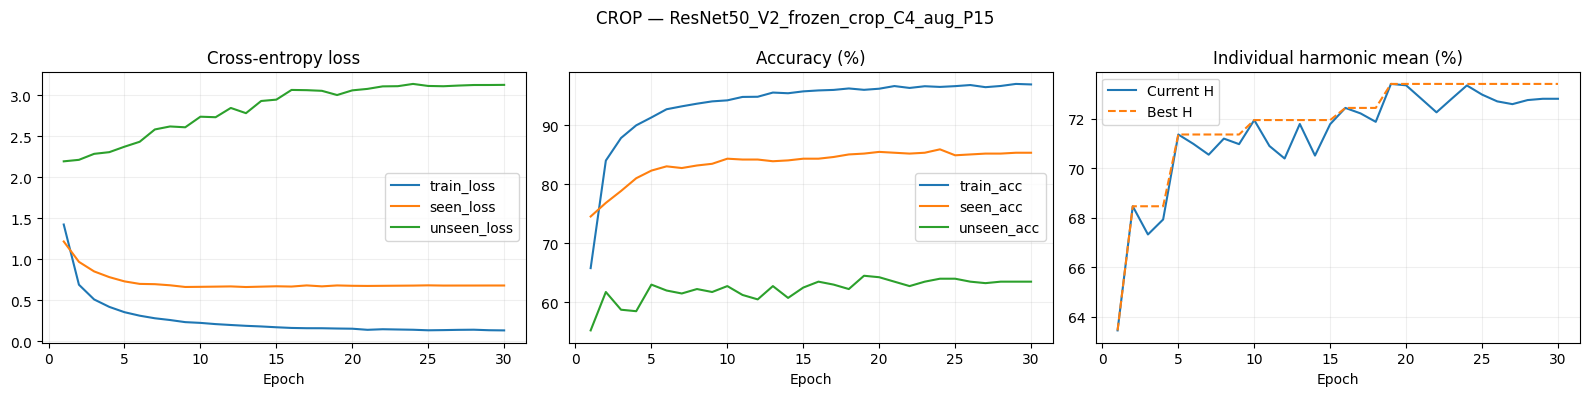

In [ ]:
train_one('frozen', 'crop')

Active strategy: frozen | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/frozen


DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 | Epoch 01/30 | Train Loss 2.5101 | Train Acc 42.16% | Seen Val 48.63% | Unseen Val 15.00% | H 22.93% | Best H 22.93% | Patience 0/15


DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 | Epoch 02/30 | Train Loss 1.4676 | Train Acc 62.58% | Seen Val 58.27% | Unseen Val 12.50% | H 20.58% | Best H 22.93% | Patience 1/15


DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 3/30:   0%|          | 0/432 [00:00<?, ?it/s]

... (45 outputs left out)

DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 26/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 | Epoch 26/30 | Train Loss 0.4208 | Train Acc 87.94% | Seen Val 66.47% | Unseen Val 15.00% | H 24.48% | Best H 25.29% | Patience 14/15


DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 27/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_frozen_disease_D1_aug_P15 | Epoch 27/30 | Train Loss 0.4043 | Train Acc 88.59% | Seen Val 65.90% | Unseen Val 14.50% | H 23.77% | Best H 25.29% | Patience 15/15
EARLY STOPPING: disease | best epoch=12 | best H=25.29%
FINISHED disease/ResNet50_V2_frozen_disease_D1_aug_P15: best epoch=12 | H=25.29%


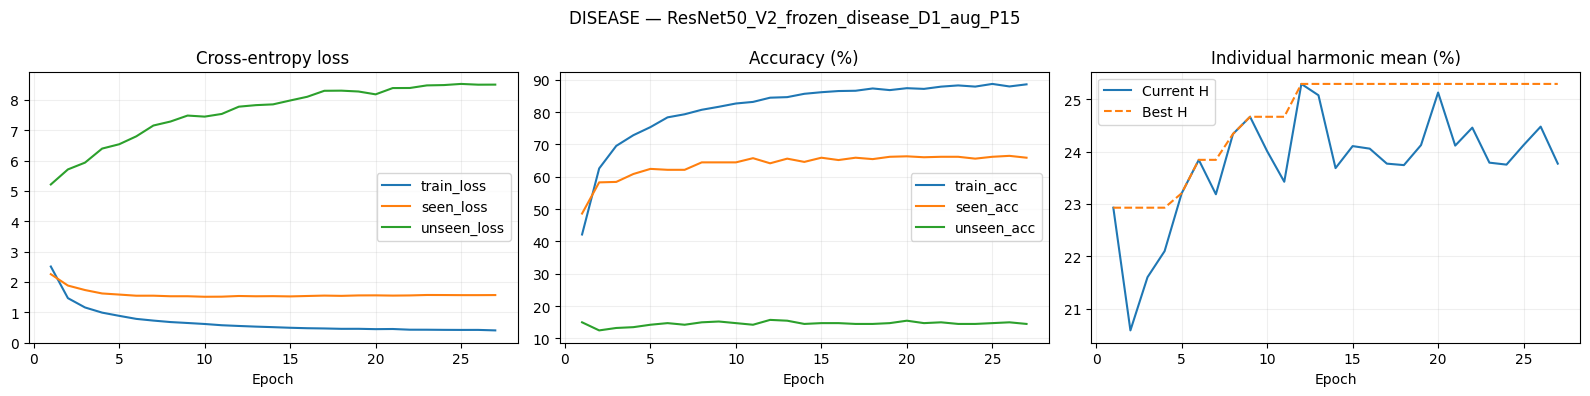

In [ ]:
train_one('frozen', 'disease')

Active strategy: partial | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/partial


CROP ResNet50_V2_partial_crop_C4_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_partial_crop_C4_aug_P15 | Epoch 01/30 | Train Loss 1.2865 | Train Acc 69.54% | Seen Val 79.28% | Unseen Val 55.25% | H 65.12% | Best H 65.12% | Patience 0/15


CROP ResNet50_V2_partial_crop_C4_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_partial_crop_C4_aug_P15 | Epoch 02/30 | Train Loss 0.4931 | Train Acc 87.36% | Seen Val 82.16% | Unseen Val 58.50% | H 68.34% | Best H 68.34% | Patience 0/15


CROP ResNet50_V2_partial_crop_C4_aug_P15 3/30:   0%|          | 0/432 [00:00<?, ?it/s]

... (39 outputs left out)

CROP ResNet50_V2_partial_crop_C4_aug_P15 23/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_partial_crop_C4_aug_P15 | Epoch 23/30 | Train Loss 0.0239 | Train Acc 99.41% | Seen Val 88.06% | Unseen Val 65.50% | H 75.12% | Best H 76.53% | Patience 14/15


CROP ResNet50_V2_partial_crop_C4_aug_P15 24/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_partial_crop_C4_aug_P15 | Epoch 24/30 | Train Loss 0.0212 | Train Acc 99.52% | Seen Val 88.06% | Unseen Val 67.25% | H 76.26% | Best H 76.53% | Patience 15/15
EARLY STOPPING: crop | best epoch=9 | best H=76.53%
FINISHED crop/ResNet50_V2_partial_crop_C4_aug_P15: best epoch=9 | H=76.53%


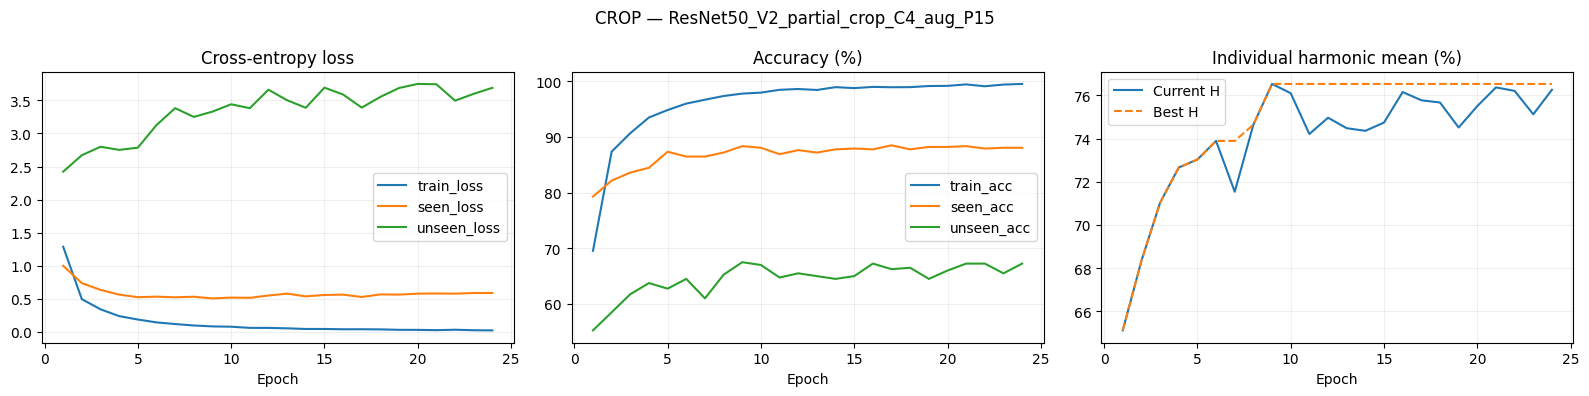

In [ ]:
train_one('partial', 'crop')

Active strategy: partial | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/partial


DISEASE ResNet50_V2_partial_disease_D1_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_partial_disease_D1_aug_P15 | Epoch 01/30 | Train Loss 2.3954 | Train Acc 44.97% | Seen Val 56.83% | Unseen Val 14.75% | H 23.42% | Best H 23.42% | Patience 0/15


DISEASE ResNet50_V2_partial_disease_D1_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_partial_disease_D1_aug_P15 | Epoch 02/30 | Train Loss 1.1949 | Train Acc 67.92% | Seen Val 63.74% | Unseen Val 15.00% | H 24.29% | Best H 24.29% | Patience 0/15


DISEASE ResNet50_V2_partial_disease_D1_aug_P15 3/30:   0%|          | 0/432 [00:00<?, ?it/s]

... (51 outputs left out)

DISEASE ResNet50_V2_partial_disease_D1_aug_P15 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_partial_disease_D1_aug_P15 | Epoch 29/30 | Train Loss 0.1088 | Train Acc 96.99% | Seen Val 72.23% | Unseen Val 19.75% | H 31.02% | Best H 31.63% | Patience 14/15


DISEASE ResNet50_V2_partial_disease_D1_aug_P15 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_partial_disease_D1_aug_P15 | Epoch 30/30 | Train Loss 0.1204 | Train Acc 96.38% | Seen Val 72.23% | Unseen Val 18.25% | H 29.14% | Best H 31.63% | Patience 15/15
EARLY STOPPING: disease | best epoch=15 | best H=31.63%
FINISHED disease/ResNet50_V2_partial_disease_D1_aug_P15: best epoch=15 | H=31.63%


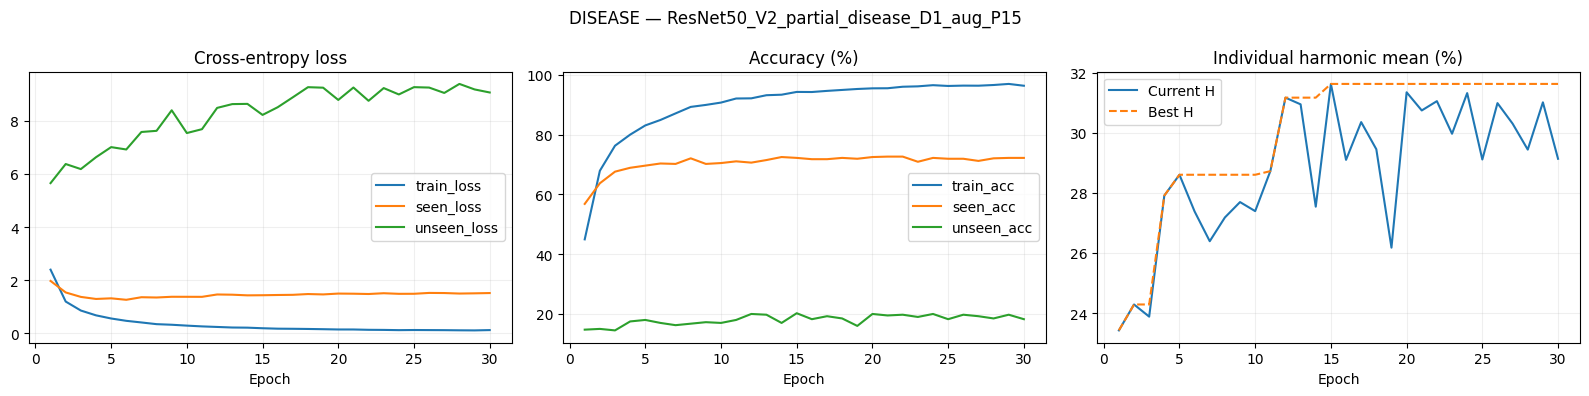

In [ ]:
train_one('partial', 'disease')

Active strategy: full | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/full


CROP ResNet50_V2_full_crop_C4_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_full_crop_C4_aug_P15 | Epoch 01/30 | Train Loss 1.3017 | Train Acc 68.62% | Seen Val 77.84% | Unseen Val 53.00% | H 63.06% | Best H 63.06% | Patience 0/15


CROP ResNet50_V2_full_crop_C4_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_full_crop_C4_aug_P15 | Epoch 02/30 | Train Loss 0.4950 | Train Acc 86.95% | Seen Val 83.60% | Unseen Val 65.75% | H 73.61% | Best H 73.61% | Patience 0/15


CROP ResNet50_V2_full_crop_C4_aug_P15 3/30:   0%|          | 0/432 [00:00<?, ?it/s]

... (51 outputs left out)

CROP ResNet50_V2_full_crop_C4_aug_P15 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_full_crop_C4_aug_P15 | Epoch 29/30 | Train Loss 0.0227 | Train Acc 99.42% | Seen Val 89.64% | Unseen Val 70.50% | H 78.93% | Best H 80.26% | Patience 7/15


CROP ResNet50_V2_full_crop_C4_aug_P15 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

CROP    ResNet50_V2_full_crop_C4_aug_P15 | Epoch 30/30 | Train Loss 0.0189 | Train Acc 99.57% | Seen Val 89.64% | Unseen Val 71.75% | H 79.70% | Best H 80.26% | Patience 8/15
FINISHED crop/ResNet50_V2_full_crop_C4_aug_P15: best epoch=22 | H=80.26%


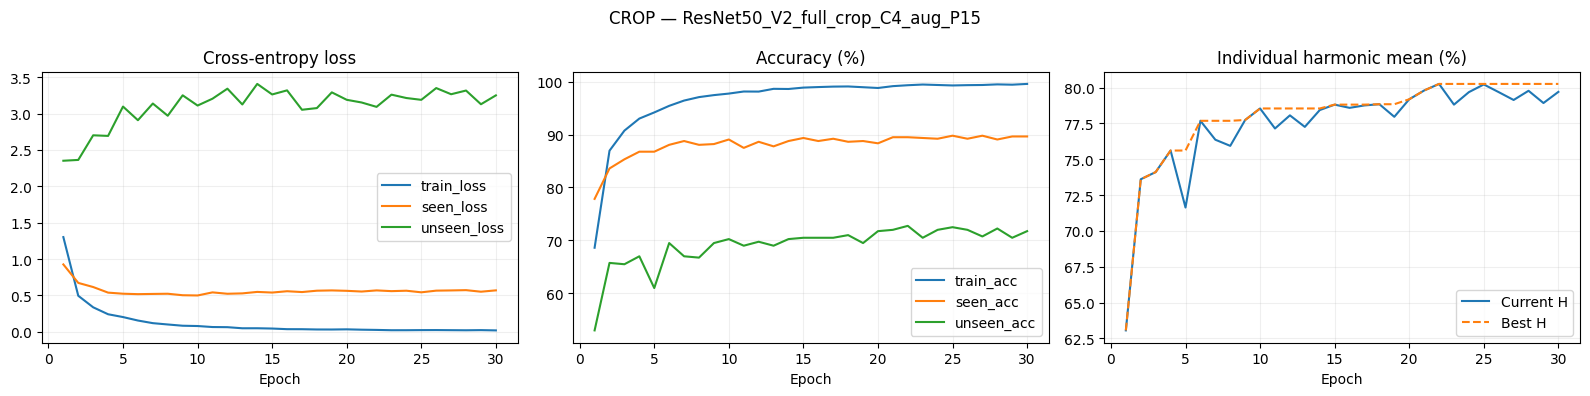

In [ ]:
train_one('full', 'crop')

In [ ]:

from pathlib import Path
from datetime import datetime
import shutil

# Select Full Fine-Tuning
activate_strategy('full')

# Locate yesterday's Full Disease experiment
name = RUN_NAMES['full']['disease']
old_dir = experiment_path('disease', name)

assert old_dir.exists(), f"Folder not found: {old_dir}"
assert (old_dir / 'best.pt').exists(), "Best checkpoint missing"
assert (old_dir / 'history.csv').exists(), "Training history missing"

# Create a separate backup location
backup_root = BASE_RESULTS / 'archived_incomplete_runs'
backup_root.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
backup_dir = backup_root / f'{name}_interrupted_{timestamp}'

assert not backup_dir.exists()

# Move old results safely, without deleting them
shutil.move(str(old_dir), str(backup_dir))

print("Old results backed up to:", backup_dir)
print("Original run folder is free:", not old_dir.exists())


Active strategy: full | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/full
Old results backed up to: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/archived_incomplete_runs/ResNet50_V2_full_disease_D1_aug_P15_interrupted_20261117_041406
Original run folder is free: True


Active strategy: full | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/full
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 133MB/s]


DISEASE ResNet50_V2_full_disease_D1_aug_P15 1/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_full_disease_D1_aug_P15 | Epoch 01/30 | Train Loss 2.4215 | Train Acc 44.88% | Seen Val 56.69% | Unseen Val 14.25% | H 22.78% | Best H 22.78% | Patience 0/15


DISEASE ResNet50_V2_full_disease_D1_aug_P15 2/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_full_disease_D1_aug_P15 | Epoch 02/30 | Train Loss 1.2272 | Train Acc 66.98% | Seen Val 65.61% | Unseen Val 13.75% | H 22.74% | Best H 22.78% | Patience 1/15


... (52 outputs left out)

DISEASE ResNet50_V2_full_disease_D1_aug_P15 29/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_full_disease_D1_aug_P15 | Epoch 29/30 | Train Loss 0.1066 | Train Acc 96.61% | Seen Val 76.55% | Unseen Val 21.25% | H 33.27% | Best H 36.54% | Patience 4/15


DISEASE ResNet50_V2_full_disease_D1_aug_P15 30/30:   0%|          | 0/432 [00:00<?, ?it/s]

DISEASE ResNet50_V2_full_disease_D1_aug_P15 | Epoch 30/30 | Train Loss 0.0999 | Train Acc 97.00% | Seen Val 76.69% | Unseen Val 21.25% | H 33.28% | Best H 36.54% | Patience 5/15
FINISHED disease/ResNet50_V2_full_disease_D1_aug_P15: best epoch=25 | H=36.54%


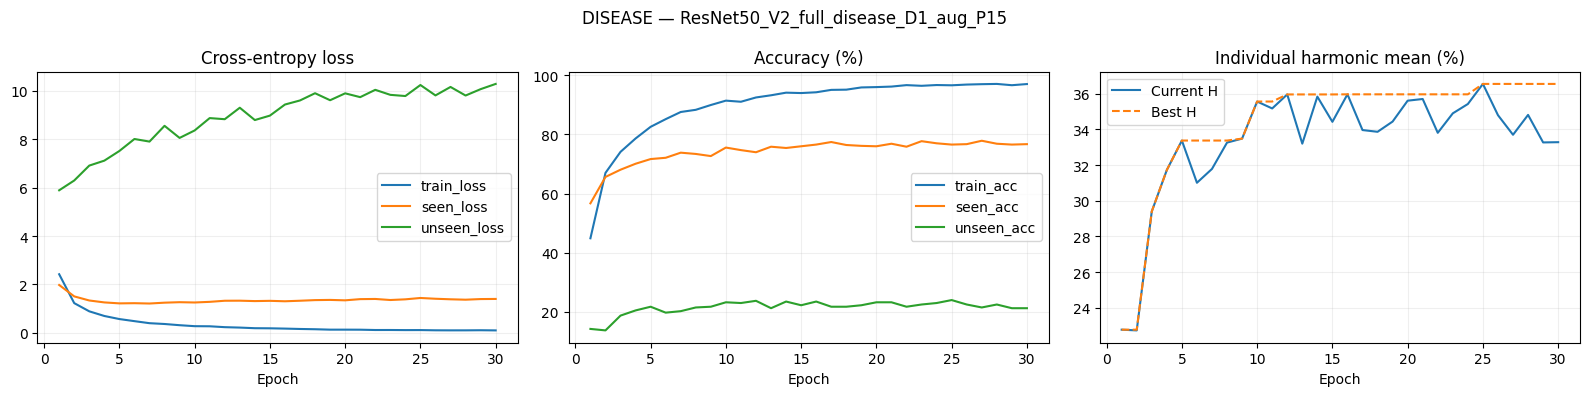

In [ ]:
train_one('full', 'disease')

In [ ]:
CANDIDATE_PAIRS = [(c,d) for c in crop_ids for d in disease_ids]
assert len(CANDIDATE_PAIRS) == 55*175 == 9625
candidate_to_index={p:i for i,p in enumerate(CANDIDATE_PAIRS)}

def composition_metrics(crop_lp,disease_lp,df,save_predictions=False):
    assert crop_lp.shape==(len(df),55), crop_lp.shape
    assert disease_lp.shape==(len(df),175), disease_lp.shape
    ctrue=np.array([crop_to_idx[int(c)] for c in df.crop_id],dtype=np.int64)
    dtrue=np.array([disease_to_idx[int(d)] for d in df.disease_id],dtype=np.int64)
    cpred=np.argsort(-crop_lp,axis=1)[:,:5]
    dpred=np.argsort(-disease_lp,axis=1)[:,:5]
    # Full 55x175 joint ranks; flatten order matches CANDIDATE_PAIRS.
    joint=(crop_lp[:,:,None]+disease_lp[:,None,:]).reshape(-1,9625)
    # Top 5 from all 9,625 (argpartition plus exact sorting inside candidate top-5).
    ix=np.argpartition(-joint,kth=4,axis=1)[:,:5]
    top5=ix[np.arange(len(df))[:,None],np.argsort(-np.take_along_axis(joint,ix,axis=1),axis=1)]
    true_ix=ctrue*175+dtrue
    metrics={
        'crop_top1':float(np.mean(cpred[:,0]==ctrue)),
        'crop_top5':float(np.mean((cpred==ctrue[:,None]).any(axis=1))),
        'disease_top1':float(np.mean(dpred[:,0]==dtrue)),
        'disease_top5':float(np.mean((dpred==dtrue[:,None]).any(axis=1))),
        'composition_top1':float(np.mean(top5[:,0]==true_ix)),
        'composition_top5':float(np.mean((top5==true_ix[:,None]).any(axis=1))),
    }
    if not save_predictions:return metrics,None
    records=[]
    for i,rec in enumerate(df.itertuples(index=False)):
        ranked=[CANDIDATE_PAIRS[int(j)] for j in top5[i]]
        records.append({
            'filename':rec.filename,
            'true_crop_id':int(rec.crop_id),'true_disease_id':int(rec.disease_id),
            'true_composition_id':int(rec.composition_id),
            'pred_crop_id':crop_ids[int(cpred[i,0])],
            'pred_disease_id':disease_ids[int(dpred[i,0])],
            'pred_pair_crop_id':ranked[0][0],
            'pred_pair_disease_id':ranked[0][1],
            'top5_compositions':json.dumps(ranked)
        })
    return metrics,pd.DataFrame(records)

print('Candidate catalogue:',len(CANDIDATE_PAIRS),'pairs')

Candidate catalogue: 9625 pairs


In [ ]:
from IPython.display import display

def evaluate_one_strategy(strategy):
    activate_strategy(strategy)
    crop_path = experiment_path('crop', RUN_NAMES[strategy]['crop']) / 'best_validation.npz'
    disease_path = experiment_path('disease', RUN_NAMES[strategy]['disease']) / 'best_validation.npz'
    if not crop_path.exists() or not disease_path.exists():
        print(f'SKIP {strategy}: train both Crop and Disease first.')
        return None
    with np.load(crop_path) as cp, np.load(disease_path) as dp:
        s, pred_s = composition_metrics(cp['seen'], dp['seen'], val_seen_df, True)
        u, pred_u = composition_metrics(cp['unseen'], dp['unseen'], val_unseen_df, True)
    h = harmonic(s['composition_top1'],u['composition_top1'])
    out = RESULTS/'development'/'combined_validation'
    out.mkdir(parents=True,exist_ok=True)
    pred_s.to_csv(out/'seen_predictions.csv',index=False)
    pred_u.to_csv(out/'unseen_predictions.csv',index=False)
    rep = dict(strategy=strategy, weights=WEIGHTS_NAME, candidate_policy=9625,
               selected_crop_run=RUN_NAMES[strategy]['crop'],
               selected_disease_run=RUN_NAMES[strategy]['disease'],
               seen=s, unseen=u, composition_h=h)
    (out/'development_metrics.json').write_text(json.dumps(rep,indent=2))
    return {'Strategy':strategy,
            'Seen Composition Top-1 (%)':100*s['composition_top1'],
            'Unseen Composition Top-1 (%)':100*u['composition_top1'],
            'Composition HM (%)':100*h,
            'Seen Crop (%)':100*s['crop_top1'],
            'Unseen Crop (%)':100*u['crop_top1'],
            'Seen Disease (%)':100*s['disease_top1'],
            'Unseen Disease (%)':100*u['disease_top1']}

rows = [r for strategy in STRATEGIES if (r:=evaluate_one_strategy(strategy)) is not None]
if rows:
    comparison = pd.DataFrame(rows).sort_values('Composition HM (%)',ascending=False)
    display(comparison.round(2))
    comparison.to_csv(BASE_RESULTS/'stage1_three_strategy_comparison.csv',index=False)
    print('Saved:',BASE_RESULTS/'stage1_three_strategy_comparison.csv')
else:
    print('No complete strategy yet. Run the training cells first.')


Active strategy: frozen | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/frozen
Active strategy: partial | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/partial
Active strategy: full | output: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/full


,Strategy,Seen Composition Top-1 (%),Unseen Composition Top-1 (%),Composition HM (%),Seen Crop (%),Unseen Crop (%),Seen Disease (%),Unseen Disease (%)
2,full,73.96,4.75,8.93,89.50,72.75,76.55,24.00
1,partial,69.21,2.50,4.83,88.49,67.50,72.23,20.25
0,frozen,61.44,2.00,3.87,85.18,64.50,64.17,15.75


Saved: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage1_three_strategy_comparison.csv


In [ ]:

# ============================================================
# UNIVERSAL STAGE 2 — RESNET-50 IMAGENET V2
# Supports: frozen / partial / full
# Training: all 8,000 images, 10 extra epochs
# Live graph after every epoch
# Saves checkpoints and supports epoch-level resume
# NO validation or official test in this stage
# ============================================================

from pathlib import Path
import os, gc, copy, json, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

S2_EPOCHS = 10
S2_BATCH_SIZE = 16
S2_BACKBONE_LR = 1e-6
S2_HEAD_LR = 1e-4
S2_WEIGHT_DECAY = 1e-4

S2_ROOT = BASE_RESULTS / "stage2_full_data"
S2_ROOT.mkdir(parents=True, exist_ok=True)

assert DEVICE.type == "cuda"
assert BACKBONE == "resnet50"
assert WEIGHTS_NAME == "IMAGENET1K_V2"
assert len(full_train_df) == 8000

# ------------------------------------------------------------
# LIVE TRAINING GRAPH
# ------------------------------------------------------------

def s2_graph(history, strategy, task, folder):
    df = pd.DataFrame(history)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(
        df["epoch"], df["train_loss"],
        marker="o", linewidth=2, label="Train Loss"
    )
    axes[0].set_title("Training Loss")
    axes[0].set_ylabel("Cross-Entropy Loss")

    axes[1].plot(
        df["epoch"], df["train_acc"] * 100,
        marker="o", linewidth=2, label="Train Accuracy"
    )
    axes[1].set_title("Training Accuracy")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_ylim(0, 105)

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.set_xticks(range(1, S2_EPOCHS + 1))
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(
        f"ResNet-50 V2 | {strategy.upper()} | "
        f"{task.upper()} | Epoch {int(df['epoch'].iloc[-1])}/{S2_EPOCHS}"
    )

    plt.tight_layout()

    fig.savefig(
        folder / "training_curves.png",
        dpi=180, bbox_inches="tight"
    )
    fig.savefig(
        folder / f"graph_epoch_{int(df['epoch'].iloc[-1]):02d}.png",
        dpi=150, bbox_inches="tight"
    )

    clear_output(wait=True)
    display(fig)
    plt.close(fig)


# ------------------------------------------------------------
# UNIVERSAL STAGE 2 TRAINING FUNCTION
# ------------------------------------------------------------

def stage2_train(strategy, task):

    assert strategy in ("frozen", "partial", "full")
    assert task in ("crop", "disease")

    # Select corresponding Stage 1 results
    activate_strategy(strategy)

    source_name = RUN_NAMES[strategy][task]
    source_ckpt = (
        experiment_path(task, source_name) / "best.pt"
    )

    assert source_ckpt.exists(), (
        f"Missing Stage 1 checkpoint: {source_ckpt}"
    )

    # Separate output for every strategy and task
    folder = S2_ROOT / strategy / task
    folder.mkdir(parents=True, exist_ok=True)

    resume_path = folder / "resume_state.pt"
    final_path = folder / "final_epoch10.pt"
    history_path = folder / "history.csv"
    config_path = folder / "config.json"

    if final_path.exists():
        print(f"{strategy}/{task} already completed.")
        print("Final checkpoint:", final_path)
        if history_path.exists():
            df = pd.read_csv(history_path)
            s2_graph(df.to_dict("records"), strategy, task, folder)
        return

    # --------------------------------------------------------
    # LOAD CORRECT STAGE 1 CHECKPOINT
    # --------------------------------------------------------

    ck = torch.load(
        source_ckpt, map_location="cpu", weights_only=False
    )

    assert ck["task"] == task
    assert ck["backbone"] == BACKBONE
    assert ck["pretrained_weights"] == WEIGHTS_NAME
    assert ck["fine_tuning"] == strategy
    assert list(ck["crop_ids"]) == list(crop_ids)
    assert list(ck["disease_ids"]) == list(disease_ids)

    cfg = dict(
        backbone_lr=S2_BACKBONE_LR,
        head_lr=S2_HEAD_LR,
        batch_size=S2_BATCH_SIZE,
        epochs=S2_EPOCHS,
        weight_decay=S2_WEIGHT_DECAY,
        dropout=ck["config"]["dropout"]
    )

    # Prevent overwriting an incomplete experiment
    if not resume_path.exists() and any(folder.iterdir()):
        raise RuntimeError(
            f"Existing output without resume checkpoint: {folder}. "
            "Inspect the folder before proceeding."
        )

    set_seed(SEED)

    model = make_model(
        task,
        pretrained=False,
        dropout=cfg["dropout"],
        strategy=strategy
    )
    model.load_state_dict(ck["state_dict"])

    # Verify actual trainable layers
    def is_trainable(name):
        if strategy == "full":
            return True
        if strategy == "partial":
            return name.startswith(("layer4.", "fc."))
        return name.startswith("fc.")

    assert all(
        p.requires_grad == is_trainable(name)
        for name, p in model.named_parameters()
    ), "Unexpected trainable-layer configuration"

    optimizer = make_optimizer(model, cfg)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=S2_EPOCHS
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=AMP
    )

    history = []
    start_epoch = 1

    # --------------------------------------------------------
    # RESUME FROM LAST COMPLETED EPOCH
    # --------------------------------------------------------

    if resume_path.exists():
        saved = torch.load(
            resume_path,
            map_location="cpu",
            weights_only=False
        )

        assert saved["strategy"] == strategy
        assert saved["task"] == task
        assert saved["config"] == cfg
        assert saved["source_checkpoint"] == str(source_ckpt)

        model.load_state_dict(saved["model_state"])
        optimizer.load_state_dict(saved["optimizer_state"])
        scheduler.load_state_dict(saved["scheduler_state"])
        scaler.load_state_dict(saved["scaler_state"])

        history = saved["history"]
        start_epoch = int(saved["epoch"]) + 1

        random.setstate(saved["python_rng"])
        np.random.set_state(saved["numpy_rng"])
        torch.set_rng_state(saved["torch_rng"])

        if saved["cuda_rng"] is not None:
            torch.cuda.set_rng_state_all(saved["cuda_rng"])

        print("Resuming from epoch", start_epoch)

    else:
        print(
            "Starting Stage 2 using Stage 1 best epoch:",
            ck["epoch"]
        )

    # IMPORTANT: ALL 8,000 TRAINING IMAGES
    full_loader = loader_for(
        full_train_df,
        train=True,
        batch_size=S2_BATCH_SIZE
    )

    if not config_path.exists():
        config_path.write_text(json.dumps({
            **cfg,
            "strategy": strategy,
            "task": task,
            "training_images": len(full_train_df),
            "source_checkpoint": str(source_ckpt),
            "source_best_epoch": int(ck["epoch"]),
            "final_selection": "fixed_epoch_10"
        }, indent=2))

    print("\nStrategy:", strategy.upper())
    print("Task:", task.upper())
    print("Training images:", len(full_train_df))
    print("Additional epochs:", S2_EPOCHS)
    print("Backbone LR:", S2_BACKBONE_LR)
    print("Head LR:", S2_HEAD_LR)

    # --------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------

    try:
        for epoch in range(start_epoch, S2_EPOCHS + 1):

            result = training_epoch(
                model,
                full_loader,
                task,
                optimizer,
                scaler,
                f"S2 {strategy.upper()} {task.upper()} "
                f"{epoch}/{S2_EPOCHS}"
            )

            scheduler.step()

            history.append({
                "epoch": epoch,
                "train_loss": result["loss"],
                "train_acc": result["top1"]
            })

            # Checkpoint after each completed epoch
            state = {
                "epoch": epoch,
                "strategy": strategy,
                "task": task,
                "config": copy.deepcopy(cfg),
                "source_checkpoint": str(source_ckpt),
                "model_state": {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                },
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(),
                "history": copy.deepcopy(history),
                "python_rng": random.getstate(),
                "numpy_rng": np.random.get_state(),
                "torch_rng": torch.get_rng_state(),
                "cuda_rng": (
                    torch.cuda.get_rng_state_all()
                    if torch.cuda.is_available() else None
                )
            }

            temp_path = folder / "resume_state.tmp"
            torch.save(state, temp_path)
            os.replace(temp_path, resume_path)

            pd.DataFrame(history).to_csv(
                history_path, index=False
            )

            # Update graph after EVERY epoch
            s2_graph(history, strategy, task, folder)

            print(
                f"{strategy.upper()} | {task.upper()} | "
                f"Epoch {epoch}/{S2_EPOCHS}"
            )
            print(f"Training Loss: {result['loss']:.4f}")
            print(f"Training Accuracy: {result['top1']:.2%}")
            print("Recovery checkpoint saved.")

        # ----------------------------------------------------
        # FINAL CHECKPOINT
        # ----------------------------------------------------

        torch.save({
            "state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "task": task,
            "backbone": BACKBONE,
            "pretrained_weights": WEIGHTS_NAME,
            "fine_tuning": strategy,
            "epoch": S2_EPOCHS,
            "config": copy.deepcopy(cfg),
            "crop_ids": crop_ids,
            "disease_ids": disease_ids,
            "seed": SEED,
            "source_checkpoint": str(source_ckpt),
            "training_stage": "stage2_full_data"
        }, final_path)

        print("\nSTAGE 2 COMPLETE")
        print("Strategy:", strategy)
        print("Task:", task)
        print("Final checkpoint:", final_path)

    finally:
        del model, optimizer, scheduler, scaler, full_loader
        gc.collect()
        torch.cuda.empty_cache()


print("\nUNIVERSAL STAGE 2 READY")
print("No training started yet.")



UNIVERSAL STAGE 2 READY
No training started yet.


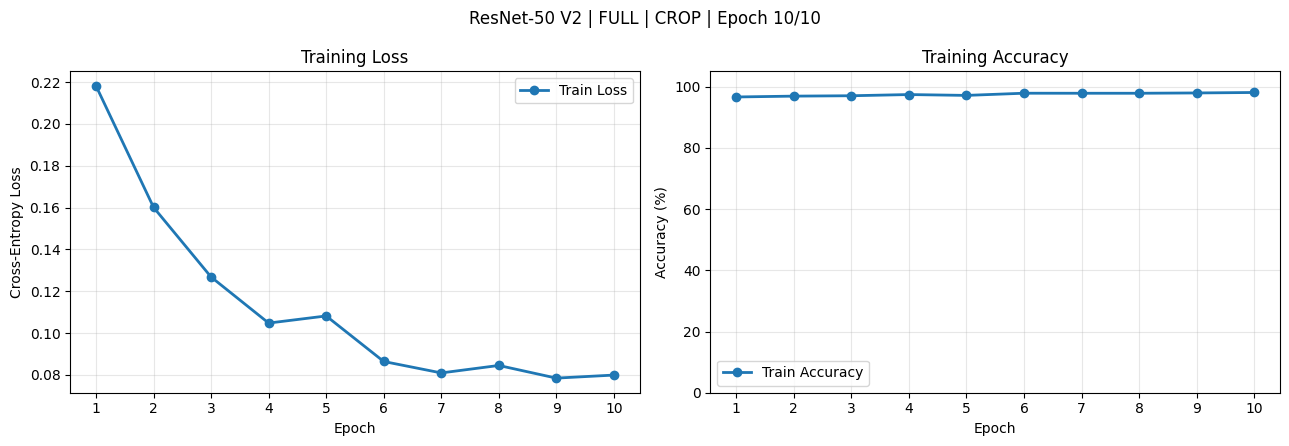

FULL | CROP | Epoch 10/10
Training Loss: 0.0799
Training Accuracy: 98.09%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: full
Task: crop
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/full/crop/final_epoch10.pt


In [ ]:

stage2_train("full", "crop")


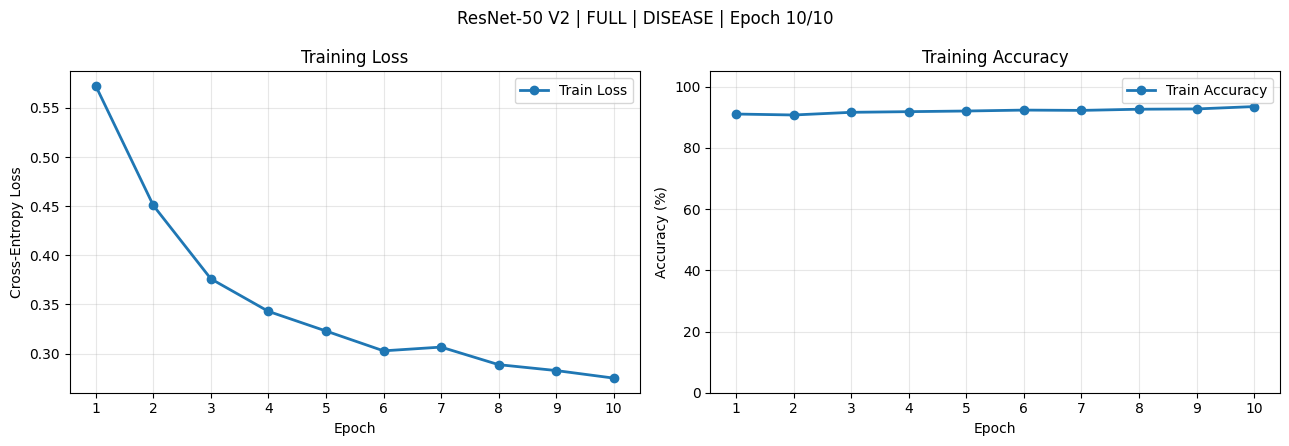

FULL | DISEASE | Epoch 10/10
Training Loss: 0.2750
Training Accuracy: 93.49%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: full
Task: disease
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/full/disease/final_epoch10.pt


In [ ]:

stage2_train("full", "disease")


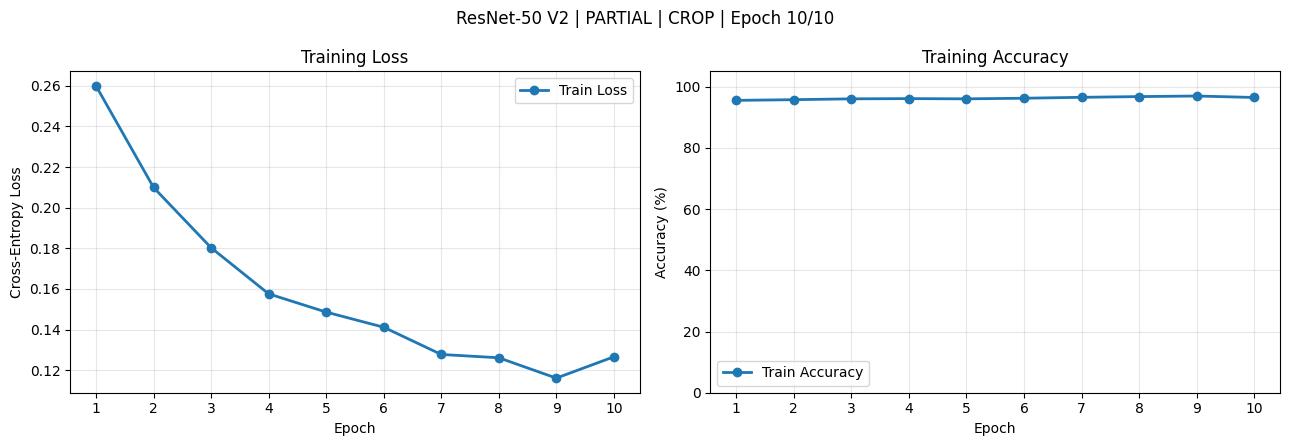

PARTIAL | CROP | Epoch 10/10
Training Loss: 0.1266
Training Accuracy: 96.46%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: partial
Task: crop
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/partial/crop/final_epoch10.pt


In [ ]:

stage2_train("partial", "crop")


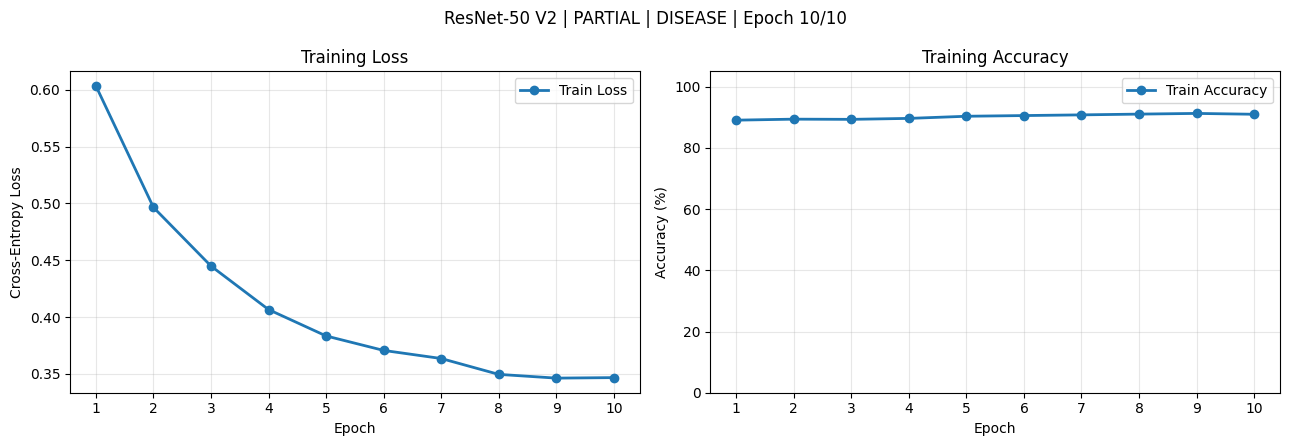

PARTIAL | DISEASE | Epoch 10/10
Training Loss: 0.3466
Training Accuracy: 90.97%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: partial
Task: disease
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/partial/disease/final_epoch10.pt


In [ ]:

stage2_train("partial", "disease")


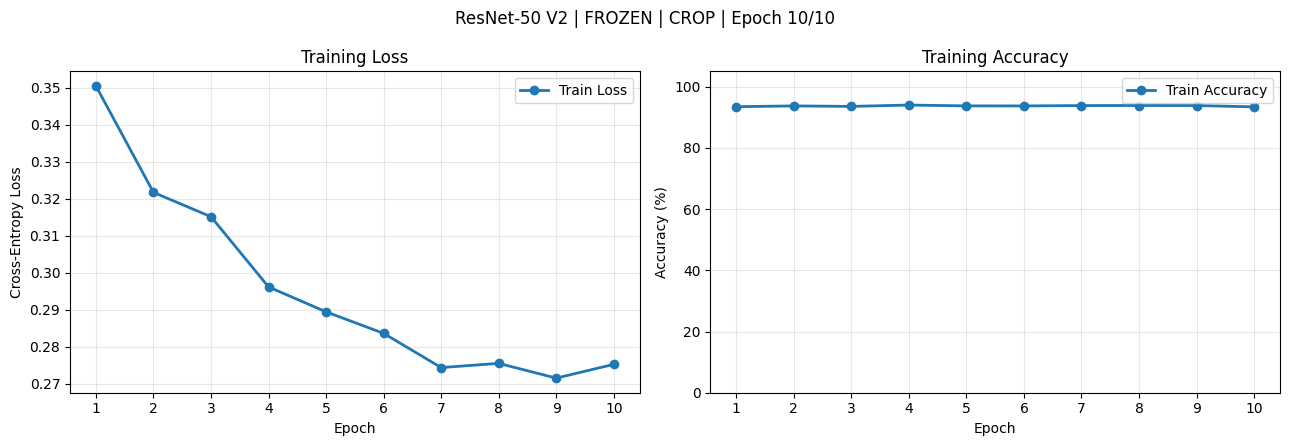

FROZEN | CROP | Epoch 10/10
Training Loss: 0.2753
Training Accuracy: 93.39%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: frozen
Task: crop
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/frozen/crop/final_epoch10.pt


In [ ]:

stage2_train("frozen", "crop")


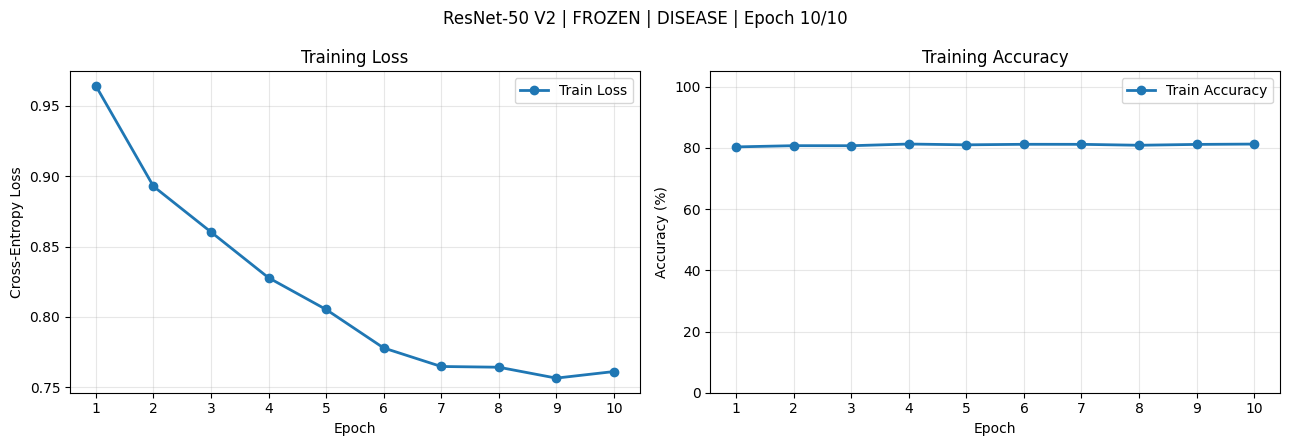

FROZEN | DISEASE | Epoch 10/10
Training Loss: 0.7612
Training Accuracy: 81.24%
Recovery checkpoint saved.

STAGE 2 COMPLETE
Strategy: frozen
Task: disease
Final checkpoint: /content/drive/MyDrive/AML_B1_ResNet50_V2_Three_Strategies_Stage1/stage2_full_data/frozen/disease/final_epoch10.pt


In [ ]:

stage2_train("frozen", "disease")


In [ ]:

from IPython.display import display

rows = []

for strategy in ["frozen", "partial", "full"]:
    for task in ["crop", "disease"]:
        folder = S2_ROOT / strategy / task
        history_path = folder / "history.csv"
        final_path = folder / "final_epoch10.pt"

        if history_path.exists():
            df = pd.read_csv(history_path)

            rows.append({
                "Strategy": strategy,
                "Task": task,
                "Epochs": len(df),
                "Training Accuracy (%)":
                    df["train_acc"].iloc[-1] * 100,
                "Training Loss":
                    df["train_loss"].iloc[-1],
                "Completed": final_path.exists()
            })
        else:
            rows.append({
                "Strategy": strategy,
                "Task": task,
                "Epochs": 0,
                "Training Accuracy (%)": None,
                "Training Loss": None,
                "Completed": False
            })

summary = pd.DataFrame(rows)
display(summary.round(2))

summary.to_csv(
    S2_ROOT / "stage2_summary.csv",
    index=False
)


,Strategy,Task,Epochs,Training Accuracy (%),Training Loss,Completed
0,frozen,crop,10,93.39,0.28,True
1,frozen,disease,10,81.24,0.76,True
2,partial,crop,10,96.46,0.13,True
3,partial,disease,10,90.98,0.35,True
4,full,crop,10,98.09,0.08,True
5,full,disease,10,93.49,0.27,True
